# 07 — Protected Attributes EDA

Thesis-critical exploratory audit of protected attributes and likely proxies in `application_train.csv` / `application_test.csv`.

## Purpose

This notebook answers fairness-prep questions before modeling and mitigation:

- How are `CODE_GENDER` and `NAME_EDUCATION_TYPE` distributed in train and test?
- What is the raw default rate by gender and by education?
- How large (and how sparse) are gender × education intersectional cells?
- Which application columns may act as proxies for gender or education?
- What descriptive outcome gaps exist **before** any model is trained?

**Context:** [01_application_eda.ipynb](01_application_eda.ipynb) · [docs/EDA.md](../../docs/EDA.md)

## Out of scope

- Credit scoring model training
- Null-importance feature selection
- Mitigation (pre / in / post)
- Final fairness metrics on out-of-fold predictions (demographic parity, equal opportunity, equalized odds)

Protected attributes are **audit-only** and must not be used as model features. Findings here are descriptive diagnostics of the data, not conclusions about a trained scorer.

## 0. Load data and define audit columns

Load application tables, set protected / intersection / proxy constants, and run basic integrity checks.

In [31]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid")

PRIMARY_KEY = "SK_ID_CURR"
PROTECTED = ["CODE_GENDER", "NAME_EDUCATION_TYPE"]
INTERSECTION = "GENDER_EDUCATION_GROUP"
PROXY_CATEGORICAL = [
    "OCCUPATION_TYPE",
    "ORGANIZATION_TYPE",
    "NAME_INCOME_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "REGION_RATING_CLIENT",
    "REGION_RATING_CLIENT_W_CITY",
]
PROXY_NUMERIC = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY"]
# Descriptive flags only — not a settled decision (see docs/open-questions.md)
SMALL_CELL_THRESHOLDS = [100, 500, 1000]

_cwd = Path.cwd()
if not (_cwd / "data" / "application_train.csv").exists():
    repo_root = (_cwd / "../..").resolve()
    if (repo_root / "data" / "application_train.csv").exists():
        os.chdir(repo_root)
    else:
        raise FileNotFoundError(
            "Place Home Credit CSVs in data/ and run with repo root or analysis/notebooks/ as cwd."
        )

DATA_DIR = Path("data")


def load_application_tables(data_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    paths = {
        "train": data_dir / "application_train.csv",
        "test": data_dir / "application_test.csv",
    }
    missing = [name for name, p in paths.items() if not p.exists()]
    if missing:
        raise FileNotFoundError(f"Missing files in {data_dir}: {missing}")
    return pd.read_csv(paths["train"]), pd.read_csv(paths["test"])


train, test = load_application_tables(DATA_DIR)

assert PRIMARY_KEY in train.columns and PRIMARY_KEY in test.columns
assert train[PRIMARY_KEY].is_unique and test[PRIMARY_KEY].is_unique
assert train[PRIMARY_KEY].notna().all() and test[PRIMARY_KEY].notna().all()
assert "TARGET" in train.columns and "TARGET" not in test.columns
assert set(PROTECTED).issubset(train.columns) and set(PROTECTED).issubset(test.columns)

print("\nCODE_GENDER (train dataset):")
print(train["CODE_GENDER"].value_counts(dropna=False))
print("\nNAME_EDUCATION_TYPE (train dataset):")
print(train["NAME_EDUCATION_TYPE"].value_counts(dropna=False))


CODE_GENDER (train dataset):
CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

NAME_EDUCATION_TYPE (train dataset):
NAME_EDUCATION_TYPE
Secondary / secondary special    218391
Higher education                  74863
Incomplete higher                 10277
Lower secondary                    3816
Academic degree                     164
Name: count, dtype: int64


## 1. Gender distribution

Compare `CODE_GENDER` counts in train vs test and raw default rates in train. Per project decisions, drop `CODE_GENDER == 'XNA'` before fairness analysis.

CODE_GENDER == 'XNA': train=4, test=0
Recommendation: exclude XNA rows from fairness grouping (already accepted in decisions).

Train vs test gender representation:


,count_train,pct_train,count_test,pct_test
CODE_GENDER,,,,
F,202448,65.83,32678.0,67.04
M,105059,34.16,16066.0,32.96
XNA,4,0.00,0.0,0.00



Train default rate by gender (includes XNA if present):


,count,pct,default_rate,defaults,default_rate_pct
CODE_GENDER,,,,,
F,202448,65.8344,0.0700,14170,6.9993
M,105059,34.1643,0.1014,10655,10.1419
XNA,4,0.0013,0.0000,0,0.0000


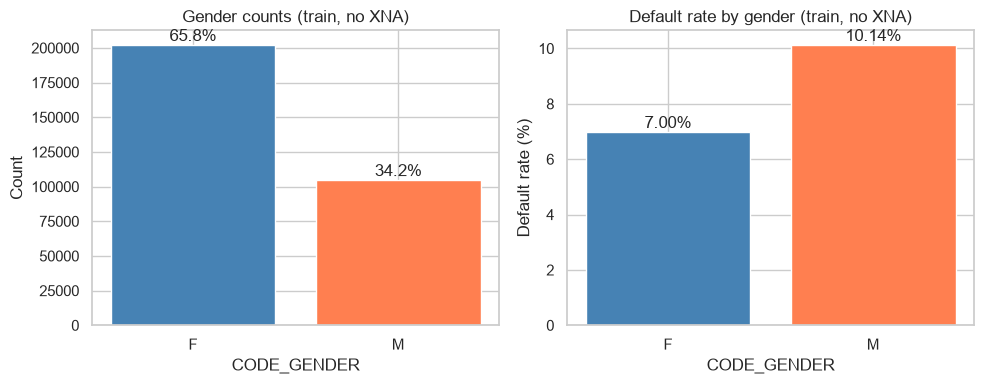

Max−min gender default-rate gap (descriptive): 3.14 percentage points


In [32]:
def group_profile(df: pd.DataFrame, col: str, with_target: bool = True) -> pd.DataFrame:
    counts = df[col].value_counts(dropna=False)
    out = pd.DataFrame({"count": counts, "pct": 100 * counts / len(df)})
    if with_target and "TARGET" in df.columns:
        rates = df.groupby(col, dropna=False)["TARGET"].agg(default_rate="mean", defaults="sum")
        out = out.join(rates)
        out["default_rate_pct"] = 100 * out["default_rate"]
    return out.sort_values("count", ascending=False)


n_xna_train = int((train["CODE_GENDER"] == "XNA").sum())
n_xna_test = int((test["CODE_GENDER"] == "XNA").sum())
print(f"CODE_GENDER == 'XNA': train={n_xna_train}, test={n_xna_test}")
print("Recommendation: exclude XNA rows from fairness grouping (already accepted in decisions).")

gender_train = group_profile(train, "CODE_GENDER", with_target=True)
gender_test = group_profile(test, "CODE_GENDER", with_target=False)
gender_compare = gender_train[["count", "pct"]].add_suffix("_train").join(
    gender_test[["count", "pct"]].add_suffix("_test"), how="outer"
).fillna(0)
print("\nTrain vs test gender representation:")
display(gender_compare.round(2))

print("\nTrain default rate by gender (includes XNA if present):")
display(gender_train.round(4))

train_no_xna = train[train["CODE_GENDER"] != "XNA"].copy()
gender_rates = group_profile(train_no_xna, "CODE_GENDER", with_target=True)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(gender_rates.index.astype(str), gender_rates["count"], color=["steelblue", "coral"])
axes[0].set_title("Gender counts (train, no XNA)")
axes[0].set_xlabel("CODE_GENDER")
axes[0].set_ylabel("Count")
for i, (idx, row) in enumerate(gender_rates.iterrows()):
    axes[0].text(i, row["count"], f"{row['pct']:.1f}%", ha="center", va="bottom")

axes[1].bar(gender_rates.index.astype(str), gender_rates["default_rate_pct"], color=["steelblue", "coral"])
axes[1].set_title("Default rate by gender (train, no XNA)")
axes[1].set_xlabel("CODE_GENDER")
axes[1].set_ylabel("Default rate (%)")
for i, (idx, row) in enumerate(gender_rates.iterrows()):
    axes[1].text(i, row["default_rate_pct"], f"{row['default_rate_pct']:.2f}%", ha="center", va="bottom")
plt.tight_layout()
plt.show()

gender_gap = gender_rates["default_rate"].max() - gender_rates["default_rate"].min()
print(f"Max−min gender default-rate gap (descriptive): {100 * gender_gap:.2f} percentage points")

**Interpretation:** Female applicants dominate the sample (~66% train). Male applicants have a higher raw default rate than female applicants. The 4 `XNA` train rows are negligible and should be dropped for fairness grouping. This is an **outcome distribution** gap in the labeled data, not yet a model fairness metric.

## 2. Education distribution

Profile `NAME_EDUCATION_TYPE` in train/test and raw default rates. Flag rare categories that can create unstable intersectional cells.

Train vs test education representation:


,count_train,pct_train,count_test,pct_test
NAME_EDUCATION_TYPE,,,,
Academic degree,164,0.05,41,0.08
Higher education,74862,24.34,12516,25.68
Incomplete higher,10276,3.34,1724,3.54
Lower secondary,3816,1.24,475,0.97
Secondary / secondary special,218389,71.02,33988,69.73



Train default rate by education:


,count,pct,default_rate,defaults,default_rate_pct
NAME_EDUCATION_TYPE,,,,,
Secondary / secondary special,218389,71.0192,0.0894,19524,8.9400
Higher education,74862,24.3448,0.0536,4009,5.3552
Incomplete higher,10276,3.3417,0.0849,872,8.4858
Lower secondary,3816,1.2409,0.1093,417,10.9277
Academic degree,164,0.0533,0.0183,3,1.8293


Rare education categories in train (<1,000 rows): ['Academic degree']


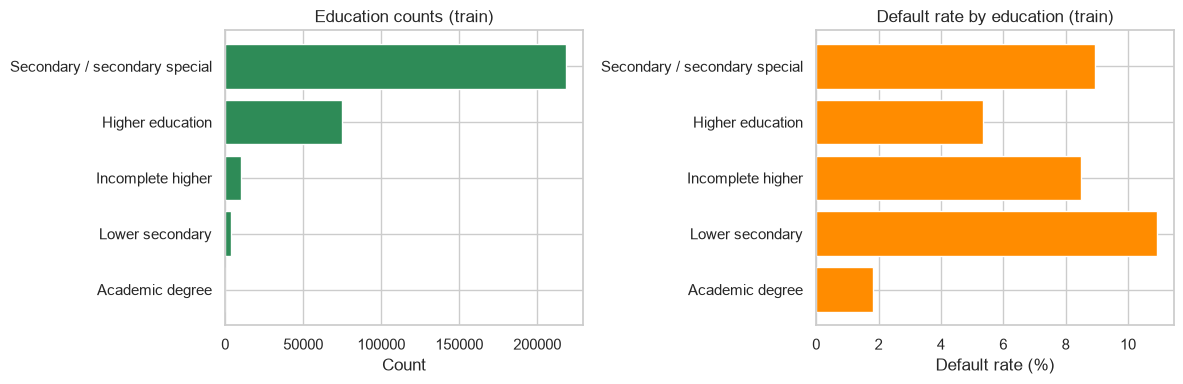

Max−min education default-rate gap (descriptive): 9.10 percentage points


In [33]:
edu_train = group_profile(train_no_xna, "NAME_EDUCATION_TYPE", with_target=True)
edu_test = group_profile(test[test["CODE_GENDER"] != "XNA"], "NAME_EDUCATION_TYPE", with_target=False)
edu_compare = edu_train[["count", "pct"]].add_suffix("_train").join(
    edu_test[["count", "pct"]].add_suffix("_test"), how="outer"
).fillna(0)
print("Train vs test education representation:")
display(edu_compare.round(2))

print("\nTrain default rate by education:")
display(edu_train.round(4))

rare_edu = edu_train[edu_train["count"] < 1000].index.tolist()
print(f"Rare education categories in train (<1,000 rows): {rare_edu}")

edu_order = edu_train.sort_values("count", ascending=True).index
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(edu_order.astype(str), edu_train.loc[edu_order, "count"], color="seagreen")
axes[0].set_title("Education counts (train)")
axes[0].set_xlabel("Count")
axes[1].barh(edu_order.astype(str), edu_train.loc[edu_order, "default_rate_pct"], color="darkorange")
axes[1].set_title("Default rate by education (train)")
axes[1].set_xlabel("Default rate (%)")
plt.tight_layout()
plt.show()

edu_gap = edu_train["default_rate"].max() - edu_train["default_rate"].min()
print(f"Max−min education default-rate gap (descriptive): {100 * edu_gap:.2f} percentage points")

**Interpretation:** Secondary education dominates (~71%). Lower secondary has the highest raw default rate; Academic degree is rare and has the lowest. Academic degree (~164 train rows) will produce very small gender × education cells.

## 3. Intersectionality: gender × education

Build `GENDER_EDUCATION_GROUP` after excluding `XNA` gender. Report counts, percentages, default rates, and small-cell flags. Minimum cell size is **not** settled yet.

Intersectional subgroup profile (train wihout 4 XNA rows):


,count,group_share,default_rate_pct
GENDER_EDUCATION_GROUP,,,
M | Academic degree,64,0.02,0.00
F | Academic degree,100,0.03,3.00
M | Lower secondary,1505,0.49,13.49
F | Lower secondary,2311,0.75,9.26
M | Incomplete higher,3993,1.30,9.22
F | Incomplete higher,6283,2.04,8.02
M | Higher education,24573,7.99,6.39
F | Higher education,50289,16.35,4.85
M | Secondary / secondary special,74924,24.36,11.36


Cells with count < 100: 1 / 10
Cells with count < 500: 2 / 10
Cells with count < 1000: 2 / 10


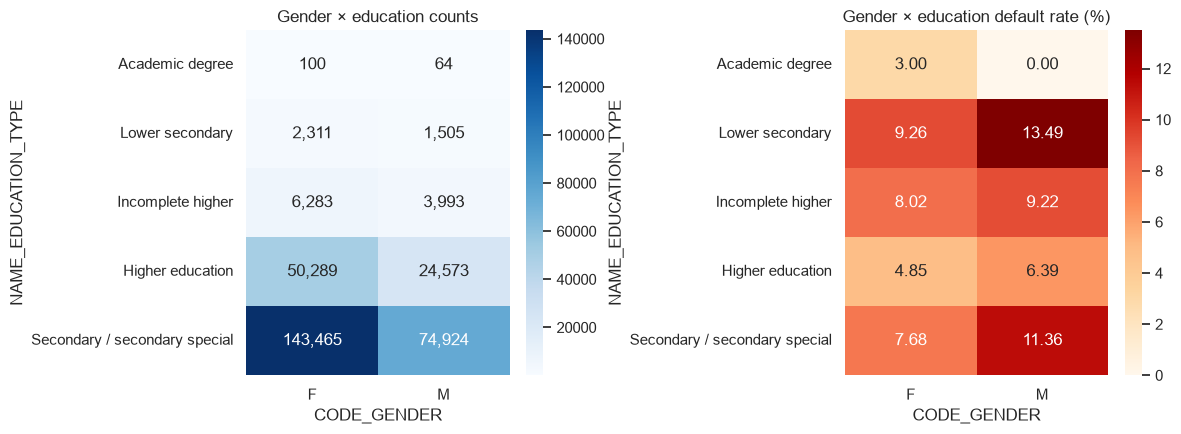

In [34]:
audit = train_no_xna.copy()
audit[INTERSECTION] = (
    audit["CODE_GENDER"].astype(str) + " | " + audit["NAME_EDUCATION_TYPE"].astype(str)
)

inter = (
    audit.groupby(INTERSECTION)["TARGET"]
    .agg(count="count", default_rate="mean")
    .assign(group_share=lambda d: 100 * d["count"] / d["count"].sum())
    .sort_values("count")
)
inter["default_rate_pct"] = 100 * inter["default_rate"]

print("Intersectional subgroup profile (train wihout 4 XNA rows):")
display(inter[["count", "group_share", "default_rate_pct"]].round(2))

for thr in SMALL_CELL_THRESHOLDS:
    inter[f"small_lt_{thr}"] = inter["count"] < thr

for thr in SMALL_CELL_THRESHOLDS:
    n_small = int(inter[f"small_lt_{thr}"].sum())
    print(f"Cells with count < {thr}: {n_small} / {len(inter)}")

# Pivot heatmaps: counts and default rates
count_pivot = (
    audit.pivot_table(index="NAME_EDUCATION_TYPE", columns="CODE_GENDER", values="TARGET", aggfunc="size")
    .reindex(index=edu_order)
)
rate_pivot = (
    audit.pivot_table(index="NAME_EDUCATION_TYPE", columns="CODE_GENDER", values="TARGET", aggfunc="mean")
    .reindex(index=edu_order)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(count_pivot, annot=True, fmt=",.0f", cmap="Blues", ax=axes[0])
axes[0].set_title("Gender × education counts")
sns.heatmap(100 * rate_pivot, annot=True, fmt=".2f", cmap="OrRd", ax=axes[1])
axes[1].set_title("Gender × education default rate (%)")
plt.tight_layout()
plt.show()

**Interpretation:** Most applicants sit in `F | Secondary / secondary special` and `M | Secondary / secondary special`. `M | Academic degree` and `F | Academic degree` are tiny. Intersectional raw default-rate spread is wider than the gender-only gap — supporting an intersectional audit later. Open questions remain: whether to merge rare education levels, what minimum cell size to require, and whether to report all cells vs worst-group only.

## 4. Raw disparity diagnostics

Summarize group outcome and representation gaps. These are **not** model fairness metrics.

In [35]:
def representation_table(train_df: pd.DataFrame, test_df: pd.DataFrame, col: str) -> pd.DataFrame:
    tr = train_df[col].value_counts(normalize=True)
    te = test_df[col].value_counts(normalize=True)
    out = pd.DataFrame({"train_share": tr, "test_share": te}).fillna(0)
    out["abs_diff_pp"] = 100 * (out["train_share"] - out["test_share"]).abs()
    return out.sort_values("train_share", ascending=False)


test_no_xna = test[test["CODE_GENDER"] != "XNA"].copy()

diagnostics = pd.DataFrame(
    [
        {
            "metric": "overall_default_rate_pct",
            "value": 100 * audit["TARGET"].mean(),
            "note": "Train baseline default rate after dropping XNA",
        },
        {
            "metric": "gender_default_gap_pp",
            "value": 100 * gender_gap,
            "note": "max−min default rate across F/M",
        },
        {
            "metric": "education_default_gap_pp",
            "value": 100 * edu_gap,
            "note": "max−min default rate across education levels",
        },
        {
            "metric": "intersection_default_gap_pp",
            "value": 100 * inter_gap,
            "note": "max−min default rate across gender×education cells",
        },
        {
            "metric": "n_intersection_cells",
            "value": len(inter),
            "note": "Number of gender×education subgroups",
        },
        {
            "metric": "n_cells_lt_100",
            "value": int(inter["small_lt_100"].sum()),
            "note": "Unstable for fine-grained metrics if kept as-is",
        },
        {
            "metric": "n_cells_lt_500",
            "value": int(inter["small_lt_500"].sum()),
            "note": "Consider merge / CI when reporting",
        },
    ]
)
display(diagnostics.round(3))

print("Gender representation train vs test (absolute share difference in pp):")
display(representation_table(audit, test_no_xna, "CODE_GENDER").round(4))
print("Education representation train vs test:")
display(representation_table(audit, test_no_xna, "NAME_EDUCATION_TYPE").round(4))

,metric,value,note
0,overall_default_rate_pct,8.073,Train baseline default rate after dropping XNA
1,gender_default_gap_pp,3.143,max−min default rate across F/M
2,education_default_gap_pp,9.098,max−min default rate across education levels
3,intersection_default_gap_pp,13.488,max−min default rate across gender×education cells
4,n_intersection_cells,10.000,Number of gender×education subgroups
5,n_cells_lt_100,1.000,Unstable for fine-grained metrics if kept as-is
6,n_cells_lt_500,2.000,Consider merge / CI when reporting


Gender representation train vs test (absolute share difference in pp):


,train_share,test_share,abs_diff_pp
CODE_GENDER,,,
F,0.6584,0.6704,1.2048
M,0.3416,0.3296,1.2048


Education representation train vs test:


,train_share,test_share,abs_diff_pp
NAME_EDUCATION_TYPE,,,
Secondary / secondary special,0.7102,0.6973,1.2916
Higher education,0.2434,0.2568,1.3322
Incomplete higher,0.0334,0.0354,0.1951
Lower secondary,0.0124,0.0097,0.2665
Academic degree,0.0005,0.0008,0.0308


**Interpretation:** Train/test gender and education mixes are similar. The descriptive outcome gap widens from gender-only to gender×education, which is why later fairness evaluation should report intersectional / worst-group results alongside gender-only metrics — once a model exists.

## 5. Proxy candidates

Inspect selected application columns that may correlate with gender or education. This is an **audit list for later FE / fairness work**, not a decision to exclude them from the model yet.

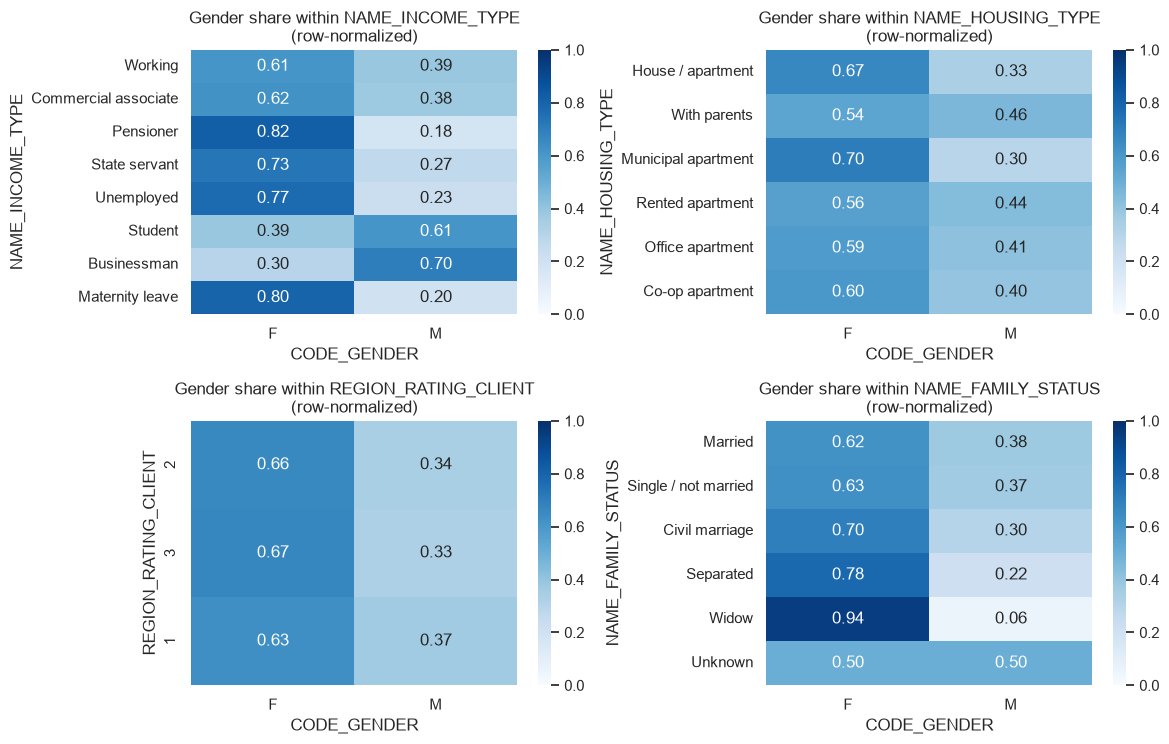

In [36]:
# Gender composition within selected categoricals (row-normalized heatmaps)
focus_cats = [
    c
    for c in ["NAME_INCOME_TYPE", "NAME_HOUSING_TYPE", "REGION_RATING_CLIENT", "NAME_FAMILY_STATUS"]
    if c in audit.columns
]

n = len(focus_cats)
n_cols = 2
n_rows = (n + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3.8 * n_rows))
axes = np.atleast_1d(axes).ravel()

for ax, col in zip(axes, focus_cats):
    ct = pd.crosstab(audit[col], audit["CODE_GENDER"], normalize="index")
    # Stable row order: most common categories first
    ct = ct.reindex(audit[col].value_counts().index)
    sns.heatmap(ct, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar=True)
    ax.set_title(f"Gender share within {col}\n(row-normalized)")
    ax.set_xlabel("CODE_GENDER")
    ax.set_ylabel(col)

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()


**Interpretation:** Each heatmap cell is the share of F/M within that category (rows sum to 1). Categories with very unbalanced gender shares (dark blue on one gender) are stronger **proxy candidates** — e.g. some income types and family/housing statuses. These associations are for monitoring in FE and later fairness work, not automatic feature exclusions. Final proxy policy remains open.

## Summary of findings

- **Protected attributes available:** `CODE_GENDER` (F / M / XNA) and `NAME_EDUCATION_TYPE` (5 levels). Audit-only — exclude from model features.
- **XNA handling:** 4 train rows with `CODE_GENDER == 'XNA'` (0 test). Drop them before fairness grouping.
- **Gender:** ~66% F / ~34% M in train; male raw default rate higher than female (~10.1% vs ~7.0%; gap ≈ 3.1 pp).
- **Education:** Secondary dominates; Lower secondary has highest raw default; Academic degree is rare (~164 train rows) and lowest default.
- **Intersectionality:** 10 gender × education cells after dropping XNA. Smallest cells: `M | Academic degree` (64) and `F | Academic degree` (100). Intersectional max−min default-rate gap (~13.5 pp) exceeds gender-only gap — report cell counts and consider worst-group metrics later.
- **Train vs test:** Gender and education mixes align closely (small share differences).
- **Proxy candidates:** `OCCUPATION_TYPE`, `ORGANIZATION_TYPE`, `NAME_INCOME_TYPE`, `NAME_FAMILY_STATUS`, `NAME_HOUSING_TYPE` and `REGION_RATING_*` show associations with gender and/or education — keep for later audit; policy undecided.